<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkST0151ENSkillsNetwork20531532-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>



# **Final Project: Boston Housing**


##### Estimated time needed: **60** minutes


#### Import the required libraries we need for the lab.


In [1]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [2]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

<ipython-input-2-b3fdaf15785b>:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


#### Read the dataset in the csv file from the URL


In [3]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [4]:
boston_df=pd.read_csv(boston_url)

#### Add your code below following the instructions given in the course to complete the peer graded assignment


In [5]:
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [6]:
boston_df.dtypes

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object

In [7]:
boston_df.isnull().sum()

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64

In [8]:
boston_df.duplicated().sum()

0

In [9]:
boston_df.corr()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
Unnamed: 0,1.000000,0.407407,-0.103393,0.399439,-0.003759,0.398736,-0.079971,0.203784,-0.302211,0.686002,0.666626,0.291074,0.258465,-0.226604
CRIM,0.407407,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305
ZN,-0.103393,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445
INDUS,0.399439,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725
CHAS,-0.003759,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260
NOX,0.398736,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321
RM,-0.079971,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360
AGE,0.203784,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955
DIS,-0.302211,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929
RAD,0.686002,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626


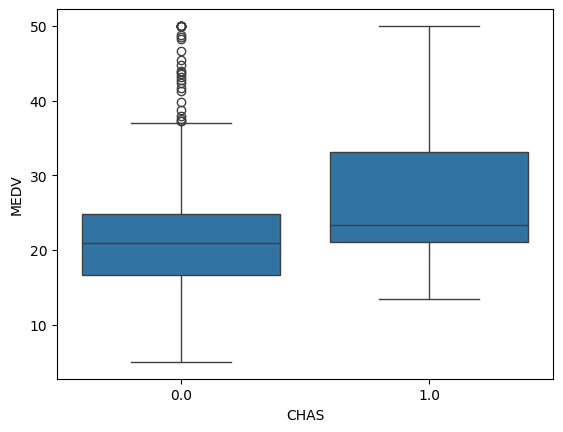

LeveneResult(statistic=8.75190489604598, pvalue=0.003238119367639829)
TtestResult(statistic=3.113291312794837, pvalue=0.003567170098137517, df=36.876408797611994)


In [10]:
sns.boxplot(x='CHAS', y='MEDV', data=boston_df)
pyplot.show()

a = boston_df[boston_df['CHAS'] == 1]['MEDV']
b = boston_df[boston_df['CHAS'] == 0]['MEDV']
print(scipy.stats.levene(a, b, center='mean'))
print(scipy.stats.ttest_ind(a, b, equal_var=False))

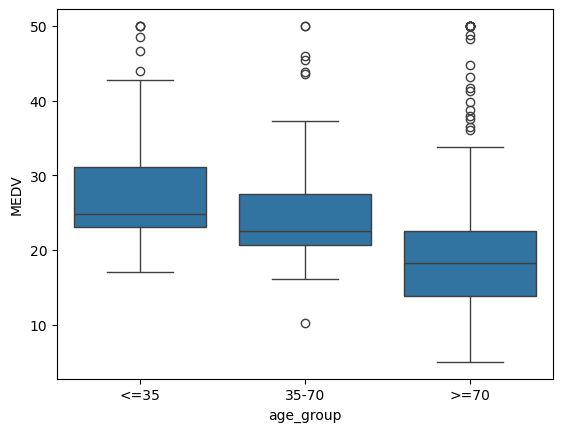

<ipython-input-11-abdde96e4782>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = [g['MEDV'] for _, g in boston_df.groupby('age_group')]


F_onewayResult(statistic=36.40764999196599, pvalue=1.7105011022702984e-15)


In [11]:
boston_df['age_group'] = pd.cut(boston_df['AGE'], [0, 35, 70, 100],
                                labels=['<=35', '35-70', '>=70'])
sns.boxplot(x='age_group', y='MEDV', data=boston_df)
pyplot.show()

groups = [g['MEDV'] for _, g in boston_df.groupby('age_group')]
print(scipy.stats.f_oneway(*groups))

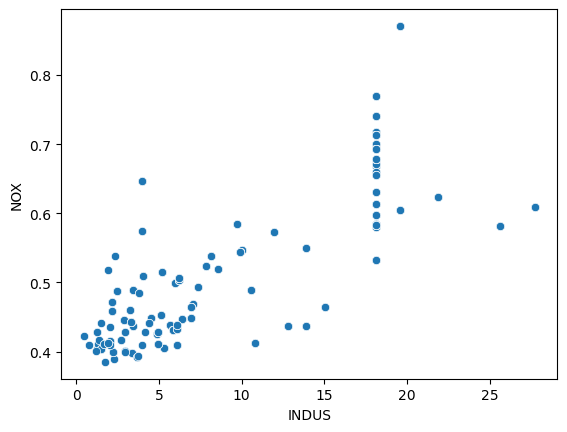

PearsonRResult(statistic=0.7636514469209192, pvalue=7.913361061210442e-98)


In [12]:
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
pyplot.show()
print(scipy.stats.pearsonr(boston_df['INDUS'], boston_df['NOX']))

In [13]:
X = sm.add_constant(boston_df['DIS'])
model = sm.OLS(boston_df['MEDV'], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        18:46:20   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

In [ ]:
# ==========================================
# FINAL PROJECT: BOSTON HOUSING DATA ANALYSIS
# ==========================================

# 1. Nhập các thư viện cần thiết
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

# 2. Tải và đọc bộ dữ liệu Boston Housing
URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
boston_df = pd.read_csv(URL)

# Hiển thị 5 dòng đầu tiên của dữ liệu
boston_df.head()

# ==========================================
# PHẦN 1: THỐNG KÊ MÔ TẢ VÀ TRỰC HÓA DỮ LIỆU (EDA)
# ==========================================

# Câu hỏi 1: Biểu đồ hộp (Boxplot) cho giá nhà (MEDV)
plt.figure(figsize=(8, 5))
sns.boxplot(y='MEDV', data=boston_df)
plt.title("Boxplot of Median Value of Owner-Occupied Homes (MEDV)")
plt.show()

# Câu hỏi 2: Biểu đồ cột (Bar plot) cho biến Charles River (CHAS)
plt.figure(figsize=(6, 4))
sns.countplot(x='CHAS', data=boston_df)
plt.title("Number of homes bound to the Charles river")
plt.show()

# Câu hỏi 3: Biểu đồ hộp cho MEDV theo nhóm tuổi (AGE)
boston_df.loc[(boston_df['AGE'] <= 35), 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70'
boston_df.loc[(boston_df['AGE'] >= 70), 'age_group'] = '70 years and older'

plt.figure(figsize=(10, 6))
sns.boxplot(x='age_group', y='MEDV', data=boston_df)
plt.title("MEDV vs Age Groups")
plt.show()

# Câu hỏi 4: Biểu đồ phân tán (Scatter plot) giữa NOX và INDUS
plt.figure(figsize=(8, 5))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
plt.title("Relationship between Nitric Oxides and Non-retail Business Acres")
plt.show()

# Câu hỏi 5: Biểu đồ Histogram cho tỷ lệ giáo viên/học sinh (PTRATIO)
plt.figure(figsize=(8, 5))
sns.histplot(boston_df['PTRATIO'], bins=20, kde=True)
plt.title("Histogram of Pupil-Teacher Ratio")
plt.show()


# ==========================================
# PHẦN 2: KIỂM ĐỊNH GIẢ THUYẾT (HYPOTHESIS TESTING)
# ==========================================

# Câu hỏi 6: Kiểm định T-test (Independent Samples t-test)
# So sánh giá nhà trung bình của các ngôi nhà gần sông Charles và không gần sông Charles
chas_0 = boston_df[boston_df['CHAS'] == 0]['MEDV']
chas_1 = boston_df[boston_df['CHAS'] == 1]['MEDV']

t_stat, p_val = scipy.stats.ttest_ind(chas_0, chas_1)
print(f"T-test results: T-statistic = {t_stat}, p-value = {p_val}")


# Câu hỏi 7: Kiểm định ANOVA
# So sánh giá nhà trung bình (MEDV) theo các nhóm tuổi (age_group)
group1 = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
group2 = boston_df[boston_df['age_group'] == 'between 35 and 70']['MEDV']
group3 = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']

f_stat, p_val_anova = scipy.stats.f_oneway(group1, group2, group3)
print(f"ANOVA results: F-statistic = {f_stat}, p-value = {p_val_anova}")


# Câu hỏi 8: Kiểm định hệ số tương quan Pearson
# Mối quan hệ giữa tỷ lệ NOX và khoảng cách đến các trung tâm việc làm (DIS)
corr, p_val_corr = scipy.stats.pearsonr(boston_df['NOX'], boston_df['DIS'])
print(f"Pearson Correlation: r = {corr}, p-value = {p_val_corr}")


# ==========================================
# PHẦN 3: PHÂN TÍCH HỒI QUY (REGRESSION ANALYSIS)
# ==========================================

# Câu hỏi 9 & 10: Hồi quy tuyến tính đơn (Simple Linear Regression)
# Đánh giá tác động của khoảng cách đến trung tâm việc làm (DIS) lên giá nhà (MEDV)
X = boston_df['DIS']
y = boston_df['MEDV']
X = sm.add_constant(X)

model = sm.OLS(y, X).fit()
predictions = model.predict(X)
model.summary()